## [Linear Regression]

In [8]:
pip install xlrd

Note: you may need to restart the kernel to use updated packages.


In [11]:
url = "http://byungwan.com/class/Coupon_Sample.xlsx"
import pandas as pd
coupon = pd.read_excel(url)
coupon.head()

,CID,Gender,Age,CClass,Discount,Visits,Email,SMS,MStatus,Purchases,Sales
0,1,0,41,2,0,1,0,1,1,1,0.92
1,2,0,41,1,0,0,0,0,0,0,0.00
2,3,0,30,2,0,3,0,0,0,1,1.54
3,4,0,28,2,0,2,0,0,0,2,0.88
4,5,1,24,2,1,5,0,0,0,2,0.53


In [12]:
coupon.shape

(499, 11)

## 1. Outliers

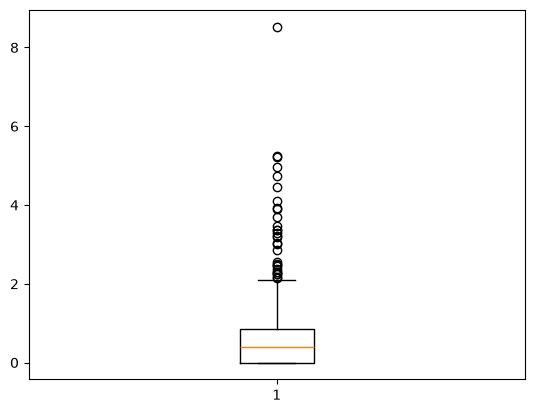

In [14]:
from matplotlib import pyplot as plt

plt.boxplot(coupon["Sales"])
plt.show()

## IQR (Inter-Quartile Range)

In [15]:
Q1 = coupon["Sales"].quantile(0.25)
Q3 = coupon["Sales"].quantile(0.75)

In [16]:
IQR = Q3-Q1

In [17]:
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

In [18]:
coupon2 = coupon[(coupon["Sales"] > lower) & (coupon["Sales"] < upper)]

In [19]:
coupon2.shape

(469, 11)

## 2. Normality

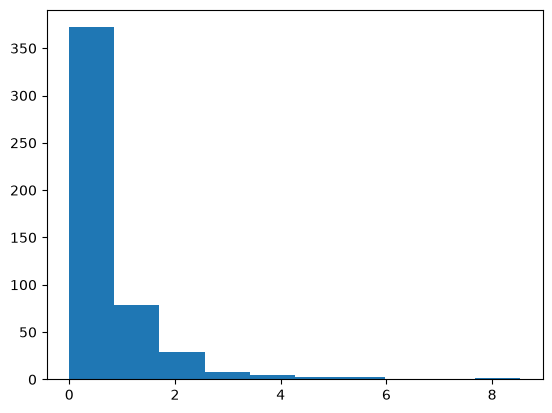

In [21]:
plt.hist(coupon["Sales"])
plt.show()

## Log Transformation

In [22]:
import numpy as np

In [23]:
coupon["Sales"].describe()

count    499.000000
mean       0.664738
std        0.918000
min        0.000000
25%        0.000000
50%        0.390000
75%        0.862500
max        8.530800
Name: Sales, dtype: float64

In [26]:
log_sales = np.log(coupon["Sales"]+1) #adding 1 to the values would prevent from having 0.00 values

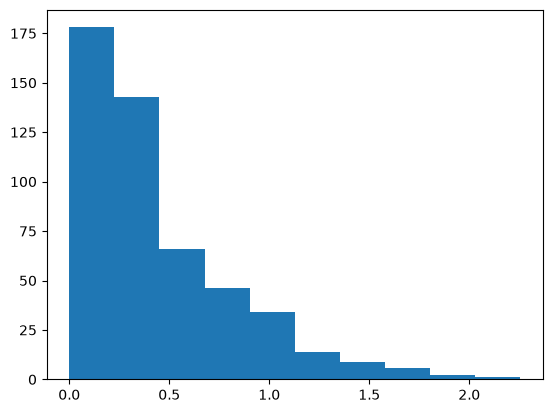

In [27]:
plt.hist(log_sales)
plt.show()

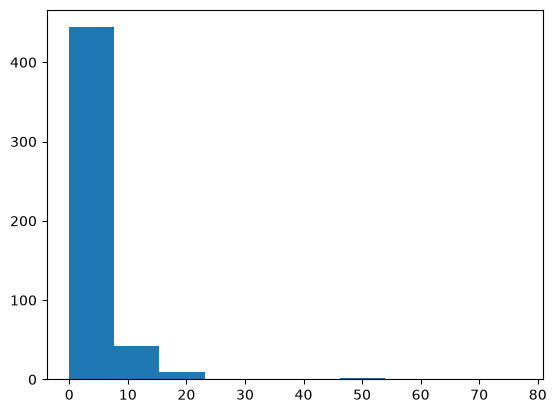

In [28]:
plt.hist(coupon["Visits"])
plt.show()

In [29]:
coupon["Visits"].describe()

count    499.000000
mean       3.392786
std        5.812156
min        0.000000
25%        1.000000
50%        2.000000
75%        4.000000
max       77.000000
Name: Visits, dtype: float64

In [31]:
log_visits = np.log(coupon["Visits"]+1)

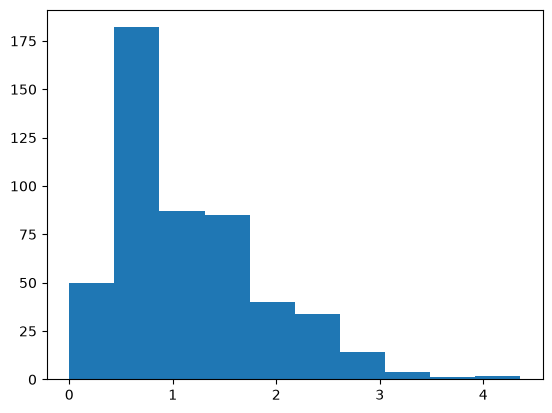

In [33]:
plt.hist(log_visits)
plt.show()

## [Missing Values]

In [37]:
url = "http://byungwan.com/class/Loan.csv"

loan = pd.read_csv(url)
loan.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [38]:
loan.shape

(614, 13)

In [42]:
loan.isnull().values.any()

np.True_

In [43]:
loan.isnull().sum()

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

## 1. Mean Substitution

In [45]:
loan["LoanAmount"].describe()

count    592.000000
mean     146.412162
std       85.587325
min        9.000000
25%      100.000000
50%      128.000000
75%      168.000000
max      700.000000
Name: LoanAmount, dtype: float64

In [48]:
LA_mean = loan["LoanAmount"].mean()

In [53]:
loan["LoanAmount"] = loan["LoanAmount"].fillna(LA_mean)

In [54]:
loan.isnull().sum()

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount            0
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

In [55]:
loan["LoanAmount"].describe()

count    614.000000
mean     146.412162
std       84.037468
min        9.000000
25%      100.250000
50%      129.000000
75%      164.750000
max      700.000000
Name: LoanAmount, dtype: float64

## 2. Mode Substitution

In [58]:
loan["Self_Employed"].value_counts()

Self_Employed
No     500
Yes     82
Name: count, dtype: int64

In [73]:
SE_mode = loan["Self_Employed"].mode()[0]

In [74]:
loan["Self_Employed"] = loan["Self_Employed"].fillna(SE_mode)

In [75]:
loan.isnull().sum()

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed         0
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount            0
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

In [76]:
loan["Self_Employed"].value_counts()

Self_Employed
No     532
Yes     82
Name: count, dtype: int64

## 3. Listwise Deletion

In [79]:
loan.shape

(614, 13)

In [80]:
loan.isnull().sum()

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed         0
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount            0
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

In [81]:
loan.dropna(inplace=True)

In [83]:
loan.shape

(524, 13)

In [84]:
loan.isnull().sum()

Loan_ID              0
Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64